# 第 15 章：布莱克–斯科尔斯–默顿模型

本章数字背后的代码：公式及其平价检验、公式必须满足的极限、公式所需的标准正态分布函数、
由历史估计与由价格反解的波动率、股息，以及处理美式期权的两种办法。

| 节 | 复现什么 |
|---|---|
| 1 | 公式、一份看涨与一份看跌期权，以及平价关系（例 15.1，图 15.1） |
| 2 | 公式在边界处的表现（第 15.5 节） |
| 3 | 计算 $N(x)$：误差函数与多项式逼近，以及远端两翼（第 15.5 节） |
| 4 | 历史波动率及其标准误差（例 15.2，表 15.1 与表 15.2） |
| 5 | 用二分法与牛顿法求隐含波动率（例 15.3，图 15.2） |
| 6 | 两种时钟：方差按交易日累积，利息按日历日累积（第 15.8 节） |
| 7 | 连续股息率（例 15.4） |
| 8 | 已知现金股息，以及 $S^*$ 的波动率（例 15.5，习题 15.16） |
| 9 | 美式看跌期权：欧式下限与二叉树（第 15.10 节） |
| 10 | 布莱克近似与二叉树（例 15.6） |
| 11 | 表 15.3 的偏斜：由表 10.2 的期权链读出（第 15.11 节） |

每个单元都把算出的值列在本章所印的值旁边，并按本章给出的小数位比较，
数字一旦漂移，就会显现出来。二叉树用 NumPy，求根与独立的正态分布函数用 SciPy，
作图用 matplotlib；其余只用标准库。

表头与图中文字保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-12s` 按字符数计；
matplotlib 的默认字体也不含中文字形。

In [1]:
from math import log, sqrt, exp, erfc, pi

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm


def show(label, got, printed, dp=4):
    """Print a computed value beside the one the chapter prints, compared at the chapter's decimals."""
    flag = "ok" if abs(got - printed) <= 0.5 * 10 ** -dp + 1e-12 else "DIFFERS"
    shown = "%14.9f" % got if 0 < abs(printed) < 0.01 else "%14.6f" % got
    print("%-50s %s   book %12s   %s" % (label, shown, "%.*f" % (dp, printed), flag))


def N(x):
    """Standard normal distribution function, from the complementary error function."""
    return 0.5 * erfc(-x / sqrt(2.0))


def bsm(S, K, r, sigma, T, q=0.0):
    """Black-Scholes-Merton d1, d2, call and put, with a continuous yield q."""
    d1 = (log(S / K) + (r - q + 0.5 * sigma * sigma) * T) / (sigma * sqrt(T))
    d2 = d1 - sigma * sqrt(T)
    call = S * exp(-q * T) * N(d1) - K * exp(-r * T) * N(d2)
    put = K * exp(-r * T) * N(-d2) - S * exp(-q * T) * N(-d1)
    return d1, d2, call, put


# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well
# as color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. 公式：一份看涨与一份看跌期权（例 15.1，图 15.1）

$c = S_0N(d_1) - Ke^{-rT}N(d_2)$，看跌期权由平价关系得出。本章手算这个例子，
在 $d_1$ 取整为 0.5157 处查表读 $N$，因此 $N(d_1)$ 所印的第五位小数来自查表；
用未取整的 $d_1$，第五位小数低两个单位，后面的结果都不受影响。

然后检验平价关系。由于 $N(d) + N(-d) = 1$，两个公式恒等地满足它：出现缺口，
必是实现上的错误，而不是建模问题；这正是检验任何定价程序时应当先做的一项。
最后一行把 $N(d_2)$ 读作风险中性的行权概率（第 15.4 节）。

In [2]:
S0, K, r, sigma, T = 58.0, 55.0, 0.04, 0.24, 0.5
d1, d2, c, p = bsm(S0, K, r, sigma, T)
disc_K = K * exp(-r * T)

show("sigma sqrt(T)", sigma * sqrt(T), 0.16971, 5)
show("ln(58/55)", log(S0 / K), 0.053110, 6)
show("(r + sigma^2/2) T", (r + 0.5 * sigma ** 2) * T, 0.034400, 6)
show("d1", d1, 0.5157)
show("d2", d2, 0.3460)
show("N(0.5157), the table lookup", N(0.5157), 0.69697, 5)
show("N(-0.5157)", N(-0.5157), 0.30303, 5)
show("N(0.3460)", N(0.3460), 0.6353)
show("N(-0.3460)", N(-0.3460), 0.3647)
print("未取整的 d1 给出 N(d1) = %.6f，即第 15.4 节的 delta" % N(d1))
show("delta N(d1), Section 15.4", N(d1), 0.6970)
print()
show("58 N(d1)", S0 * N(0.5157), 40.42, 2)
show("55 e^{-0.02} N(d2)", disc_K * N(0.3460), 34.25, 2)
show("call", c, 6.17, 2)
show("55 e^{-0.02} N(-d2)", disc_K * N(-0.3460), 19.66, 2)
show("58 N(-d1)", S0 * N(-0.5157), 17.58, 2)
show("put", p, 2.08, 2)
print()
show("call, unrounded", c, 6.1731)
show("put, unrounded", p, 2.0840)
show("c - p", c - p, 4.0891)
show("K e^{-rT}", disc_K, 53.9109)
show("S0 - K e^{-rT}", S0 - disc_K, 4.0891)

gap = max(abs(bsm(s, K, r, v, t)[2] - bsm(s, K, r, v, t)[3] - (s - K * exp(-r * t)))
          for s in (20.0, 58.0, 150.0) for v in (0.02, 0.24, 2.0) for t in (0.01, 0.5, 10.0))
print("27 组输入下平价关系的最大缺口：%.1e，只是舍入误差" % gap)
show("N(d2) as an exercise probability, percent", 100 * N(d2), 64, 0)

sigma sqrt(T)                                            0.169706   book      0.16971   ok
ln(58/55)                                                0.053110   book     0.053110   ok
(r + sigma^2/2) T                                        0.034400   book     0.034400   ok
d1                                                       0.515657   book       0.5157   ok
d2                                                       0.345951   book       0.3460   ok
N(0.5157), the table lookup                              0.696968   book      0.69697   ok
N(-0.5157)                                               0.303032   book      0.30303   ok
N(0.3460)                                                0.635329   book       0.6353   ok
N(-0.3460)                                               0.364671   book       0.3647   ok
未取整的 d1 给出 N(d1) = 0.696953，即第 15.4 节的 delta
delta N(d1), Section 15.4                                0.696953   book       0.6970   ok

58 N(d1)                                    

图 15.1 按三个到期期限画出看涨期权价值对股价的关系，$K = 50$，$r = 4\%$，$\sigma = 30\%$。
图中 48 个点在这里全部重算；曲线高出内在价值的部分即时间价值，在平值附近最宽，
并随 $T$ 缩短而收窄。

Figure 15.1 points that reproduce, of 48                48.000000   book           48   ok


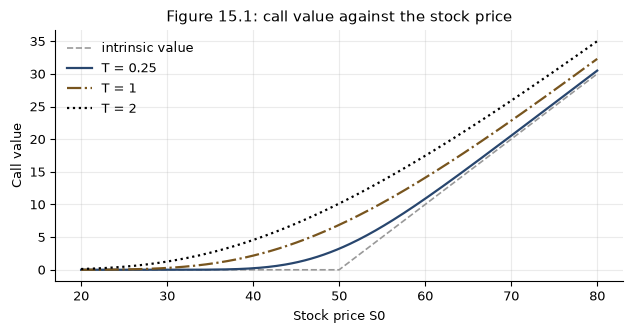

In [3]:
FIG_15_1 = {
    0.25: (0.0000, 0.0000, 0.0001, 0.0031, 0.0383, 0.2332, 0.8617, 2.2246, 4.4445, 7.4088,
           10.8833, 14.6470, 18.5512, 22.5155, 26.5032, 30.4993),
    1.0: (0.0046, 0.0356, 0.1560, 0.4729, 1.1097, 2.1674, 3.6990, 5.7059, 8.1495, 10.9679,
          14.0921, 17.4554, 20.9999, 24.6783, 28.4535, 32.2978),
    2.0: (0.1161, 0.3702, 0.8815, 1.7269, 2.9497, 4.5601, 6.5424, 8.8642, 11.4851, 14.3624,
          17.4549, 20.7255, 24.1416, 27.6755, 31.3042, 35.0088),
}
bad = 0
for t, printed in FIG_15_1.items():
    for i, value in enumerate(printed):
        if abs(bsm(20.0 + 4 * i, 50.0, 0.04, 0.30, t)[2] - value) > 0.5e-4:
            bad += 1
show("Figure 15.1 points that reproduce, of 48", 48 - bad, 48, 0)

grid = np.linspace(20.0, 80.0, 241)
fig, ax = plt.subplots()
ax.plot(grid, np.maximum(grid - 50.0, 0.0), color="0.6", ls="--", lw=1.2, label="intrinsic value")
for t, color, ls in ((0.25, BLUE, "-"), (1.0, AMBER, "-."), (2.0, "black", ":")):
    ax.plot(grid, [bsm(s, 50.0, 0.04, 0.30, t)[2] for s in grid], color=color, ls=ls, lw=1.6,
            label="T = %g" % t)
ax.set_xlabel("Stock price S0"); ax.set_ylabel("Call value")
ax.set_title("Figure 15.1: call value against the stock price")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. 公式在边界处的表现（第 15.5 节）

每一个极限都重现了第 11 章不借助任何模型得到的边界。下面的“极限”用有限值代替
（股价 5,000、波动率 0.01% 或 5,000%、只剩几秒的期限），已足以使公式在所印精度上
落在边界上。看跌期权各行等于看涨期权相应各行加上 $Ke^{-rT} - S_0$，这仍是平价关系。

In [4]:
def call(S, sig=sigma, t=T):
    return bsm(S, K, r, sig, t)[2]


def put(S, sig=sigma, t=T):
    return bsm(S, K, r, sig, t)[3]


rows = (
    ("call, S0 -> infinity: S0 - K e^{-rT}", call(5000.0), 5000.0 - disc_K),
    ("call, S0 -> 0: zero", call(0.01), 0.0),
    ("call, sigma -> 0, S0 = 58: S0 - K e^{-rT}", call(58.0, sig=1e-4), 58.0 - disc_K),
    ("call, sigma -> 0, S0 = 53 < K e^{-rT}: zero", call(53.0, sig=1e-4), 0.0),
    ("call, sigma -> infinity: S0", call(58.0, sig=50.0), 58.0),
    ("call, T -> 0: max(S0 - K, 0)", call(58.0, t=1e-4 / 365), 3.0),
    ("put, S0 -> infinity: zero", put(5000.0), 0.0),
    ("put, S0 -> 0: K e^{-rT}", put(1e-9), disc_K),
    ("put, sigma -> 0, S0 = 53: K e^{-rT} - S0", put(53.0, sig=1e-4), disc_K - 53.0),
    ("put, sigma -> infinity: K e^{-rT}", put(58.0, sig=50.0), disc_K),
    ("put, T -> 0, S0 = 50: max(K - S0, 0)", put(50.0, t=1e-4 / 365), 5.0),
)
print("%-46s %12s %12s %10s" % ("limit", "formula", "bound", "gap"))
for label, value, bound in rows:
    print("%-46s %12.6f %12.6f %10.1e" % (label, value, bound, value - bound))
print("最大缺口：%.1e" % max(abs(v - b) for _, v, b in rows))

limit                                               formula        bound        gap
call, S0 -> infinity: S0 - K e^{-rT}            4946.089073  4946.089073    0.0e+00
call, S0 -> 0: zero                                0.000000     0.000000    0.0e+00
call, sigma -> 0, S0 = 58: S0 - K e^{-rT}          4.089073     4.089073    0.0e+00
call, sigma -> 0, S0 = 53 < K e^{-rT}: zero        0.000000     0.000000    0.0e+00
call, sigma -> infinity: S0                       58.000000    58.000000    0.0e+00
call, T -> 0: max(S0 - K, 0)                       3.000001     3.000000    6.0e-07
put, S0 -> infinity: zero                          0.000000     0.000000   9.4e-157
put, S0 -> 0: K e^{-rT}                           53.910927    53.910927   -1.0e-09
put, sigma -> 0, S0 = 53: K e^{-rT} - S0           0.910927     0.910927    0.0e+00
put, sigma -> infinity: K e^{-rT}                 53.910927    53.910927    0.0e+00
put, T -> 0, S0 = 50: max(K - S0, 0)               4.999999     5.000000   -

## 3. 计算 $N(x)$（第 15.5 节）

定价程序库用双精度互补误差函数按 $N(x) = \operatorname{erfc}(-x/\sqrt{2})/2$ 计算，
上面的 `N` 就是这样做的。本章所印的多项式，绝对误差不超过 $7.5 \times 10^{-8}$；
前几行在细密网格上确认这一上界。

本章的警告针对的是*相对*误差。在远端两翼，$N(-d)$ 约为 $10^{-6}$，$10^{-8}$ 的绝对误差
就不再算小；而由深度虚值期权价格读出的隐含波动率，还要把这个误差除以一个很小的 vega。
下表显示，从 $x = 2$ 到 $x = 6$，尾部概率的相对误差增大了三个数量级；以例 15.3 的股票为标的的
虚值看跌期权，执行价离平值越远，隐含波动率偏离真实的 29.85% 越多。这里的偏离仍然不大；
要点在于方向，以及它在平值附近根本看不出来。

In [5]:
GAMMA = 0.2316419
A = (0.319381530, -0.356563782, 1.781477937, -1.821255978, 1.330274429)


def poly_tail(x):
    """1 - N(x) for x >= 0 from the chapter's polynomial, computed directly rather than by subtraction."""
    k = 1.0 / (1.0 + GAMMA * x)
    return exp(-0.5 * x * x) / sqrt(2.0 * pi) * sum(a * k ** (j + 1) for j, a in enumerate(A))


def N_poly(x):
    return 1.0 - poly_tail(x) if x >= 0 else poly_tail(-x)


xs = np.linspace(0.0, 8.0, 8001)
worst = max(abs(N_poly(x) - N(x)) for x in xs)
print("多项式在 [0, 8] 上的最大绝对误差：%.2e（本章：7.5e-8）" % worst)
print("同一网格上 erfc 算法与 scipy.stats.norm.cdf 之差：%.1e"
      % max(abs(N(x) - norm.cdf(x)) for x in xs))
print()
print("%6s %14s %14s %14s" % ("x", "N(-x)", "polynomial", "rel. error"))
for x in (2.0, 3.0, 4.0, 4.75, 5.0, 6.0):
    exact = N(-x)
    print("%6.2f %14.6e %14.6e %14.2e" % (x, exact, poly_tail(x), poly_tail(x) / exact - 1.0))


def put_with(Nf, S, K_, r_, sig, t):
    d1_ = (log(S / K_) + (r_ + 0.5 * sig * sig) * t) / (sig * sqrt(t))
    return K_ * exp(-r_ * t) * Nf(-d1_ + sig * sqrt(t)) - S * Nf(-d1_)


print()
print("%8s %14s %16s %18s" % ("strike", "put price", "implied vol", "error, vol bp"))
for strike in (20.0, 18.0, 16.0, 14.0, 13.0, 12.0):
    price = put_with(N, 21.0, strike, 0.03, 0.2985, 0.25)
    iv = brentq(lambda v: put_with(N_poly, 21.0, strike, 0.03, v, 0.25) - price, 0.05, 2.0, xtol=1e-14)
    print("%8.2f %14.8f %15.6f%% %18.4f" % (strike, price, 100 * iv, 1e4 * (iv - 0.2985)))

多项式在 [0, 8] 上的最大绝对误差：7.45e-08（本章：7.5e-8）


同一网格上 erfc 算法与 scipy.stats.norm.cdf 之差：2.2e-16

     x          N(-x)     polynomial     rel. error
  2.00   2.275013e-02   2.275006e-02      -3.07e-06
  3.00   1.349898e-03   1.349967e-03       5.13e-05
  4.00   3.167124e-05   3.168603e-05       4.67e-04
  4.75   1.017083e-06   1.018328e-06       1.22e-03
  5.00   2.866516e-07   2.871050e-07       1.58e-03
  6.00   9.865876e-10   9.901219e-10       3.58e-03

  strike      put price      implied vol      error, vol bp
   20.00     0.72553739       29.849977%            -0.0023
   18.00     0.20472373       29.850046%             0.0046
   16.00     0.03230157       29.849902%            -0.0098
   14.00     0.00216205       29.850899%             0.0899
   13.00     0.00035812       29.852126%             0.2126
   12.00     0.00004012       29.853722%             0.3722


## 4. 历史波动率（例 15.2，表 15.1 与表 15.2）

十个日收盘价、十个对数收益率、样本标准差，再按 $\sqrt{252}$ 年化。然后把例题的三条告诫
变成数字：标准误差 $\sigma/\sqrt{2n}$ 及其对应的两倍标准误差区间；用 365 天而不是 252 天
年化造成的高估（同时列出 242 天，即第 15.12 节所说的境内交易日数，$\sqrt{242} = 15.56$）；
以及略去均值的影响。

表 15.2 把标准误差折算成价格：例 15.1 的看涨期权在 24% 两侧相差 5 个和 10 个百分点的
波动率下的价值；最外两行大致位于两倍标准误差处。

In [6]:
closes = [50.00, 50.75, 50.20, 51.30, 51.05, 50.40, 51.10, 51.85, 51.60, 52.30, 52.00]
u = np.diff(np.log(closes))
printed_u = (0.014889, -0.010897, 0.021676, -0.004885, -0.012814,
             0.013793, 0.014570, -0.004833, 0.013475, -0.005753)
show("Table 15.1 returns that reproduce, of 10",
     sum(abs(a - b) <= 0.5e-6 for a, b in zip(u, printed_u)), 10, 0)
n = len(u)
show("sum u_i", u.sum(), 0.039221, 6)
show("sum u_i^2", (u ** 2).sum(), 0.00163889, 8)
s2 = ((u ** 2).sum() - u.sum() ** 2 / n) / (n - 1)
show("s^2", s2, 0.000165007, 9)
s = sqrt(s2)
show("s per day", s, 0.012846, 6)
show("np.std(u, ddof=1), the same thing", np.std(u, ddof=1), 0.012846, 6)
show("sqrt(252)", sqrt(252), 15.8745)
vol = 100 * s * sqrt(252)
show("annualized volatility, percent", vol, 20.4, 1)

se = 20.4 / sqrt(2 * n)
show("standard error sigma/sqrt(2n), points", se, 4.6, 1)
show("lower end of the 2-standard-error band, percent", 20.4 - 2 * se, 11, 0)
show("upper end of the 2-standard-error band, percent", 20.4 + 2 * se, 30, 0)

for days in (252, 365, 242):
    print("按 sqrt(%d) = %.4f 年化：%.2f%%" % (days, sqrt(days), 100 * s * sqrt(days)))
show("overstatement from 365 days, percent", 100 * (sqrt(365 / 252) - 1), 20, 0)

s_zero_mean = sqrt((u ** 2).sum() / n)
show("s with the mean dropped, divided by n", s_zero_mean, 0.012802, 6)
show("change in the annualized figure, points", vol - 100 * s_zero_mean * sqrt(252), 0.1, 1)

Table 15.1 returns that reproduce, of 10                10.000000   book           10   ok
sum u_i                                                  0.039221   book     0.039221   ok
sum u_i^2                                             0.001638891   book   0.00163889   ok
s^2                                                   0.000165007   book  0.000165007   ok
s per day                                                0.012846   book     0.012846   ok
np.std(u, ddof=1), the same thing                        0.012846   book     0.012846   ok
sqrt(252)                                               15.874508   book      15.8745   ok
annualized volatility, percent                          20.391619   book         20.4   ok
standard error sigma/sqrt(2n), points                    4.561579   book          4.6   ok
lower end of the 2-standard-error band, percent         11.276843   book           11   ok
upper end of the 2-standard-error band, percent         29.523157   book           30   ok

In [7]:
base = bsm(58.0, 55.0, 0.04, 0.24, 0.5)[2]
print("%8s %12s %12s %10s" % ("sigma", "call value", "difference", "percent"))
TABLE_15_2 = ((0.14, 4.8292, -1.3440, -21.8), (0.19, 5.4736, -0.6995, -11.3),
              (0.29, 6.9003, 0.7272, 11.8), (0.34, 7.6428, 1.4697, 23.8))
for sig, value, diff, pct in TABLE_15_2:
    v = bsm(58.0, 55.0, 0.04, sig, 0.5)[2]
    print("%7.0f%% %12.4f %+12.4f %+9.1f%%" % (100 * sig, v, v - base, 100 * (v - base) / base))
    show("  sigma = %.0f%%: value" % (100 * sig), v, value)
    show("  sigma = %.0f%%: difference" % (100 * sig), v - base, diff)
    show("  sigma = %.0f%%: percent" % (100 * sig), 100 * (v - base) / base, pct, 1)
se24 = 24 / sqrt(20)
print("24%% 处的两倍标准误差：+/-%.1f 个百分点；最外两行距中心 %.1f 个标准误差"
      % (2 * se24, 10 / se24))

   sigma   call value   difference    percent
     14%       4.8292      -1.3440     -21.8%
  sigma = 14%: value                                     4.829152   book       4.8292   ok
  sigma = 14%: difference                               -1.343952   book      -1.3440   ok
  sigma = 14%: percent                                 -21.771088   book        -21.8   ok
     19%       5.4736      -0.6995     -11.3%
  sigma = 19%: value                                     5.473579   book       5.4736   ok
  sigma = 19%: difference                               -0.699524   book      -0.6995   ok
  sigma = 19%: percent                                 -11.331807   book        -11.3   ok
     29%       6.9003      +0.7272     +11.8%
  sigma = 29%: value                                     6.900325   book       6.9003   ok
  sigma = 29%: difference                                0.727222   book       0.7272   ok
  sigma = 29%: percent                                  11.780491   book         11.8   

## 5. 隐含波动率（例 15.3，图 15.2）

看涨期权价值随 $\sigma$ 严格递增，因此反解只有一个答案。二分法慢而稳妥：它不断把一个
已知包含根的区间对半缩小。牛顿法利用斜率（即 vega），从合理的初值出发几步就收敛。
两者都得到 29.85%，SciPy 的 `brentq` 也是如此。

这张图说明了本章为什么从虚值期权读隐含波动率。在约 5% 以下，看涨期权价值紧贴下界
$S_0 - Ke^{-rT}$，曲线在那里几乎是平的；随后的表度量了这一点的后果：0.001 美元
的价格误差，在 30% 处使隐含波动率只移动零点零几个百分点，在 4% 处超过一个百分点，
在 2% 处价格已完全无法确定波动率。换用同一执行价的看跌期权并不会使曲线变陡，因为两者
vega 相同；改变的是看跌期权的价格全是时间价值，整个价格都携带波动率信息。由平价关系，
它隐含同样的 29.85%。

In [8]:
S_iv, K_iv, r_iv, T_iv, market = 21.0, 20.0, 0.03, 0.25, 1.875

for sig, printed in ((0.20, 1.5148), (0.30, 1.8807), (0.29, 1.8429)):
    show("call at sigma = %.0f%%" % (100 * sig), bsm(S_iv, K_iv, r_iv, sig, T_iv)[2], printed)


def implied_bisection(price, S, K_, r_, t, q=0.0, leg=2, lo=1e-4, hi=5.0, tol=1e-10):
    """Halve [lo, hi] until it is narrower than tol; leg 2 is the call, 3 the put."""
    steps = 0
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        if bsm(S, K_, r_, mid, t, q)[leg] < price:
            lo = mid
        else:
            hi = mid
        steps += 1
    return 0.5 * (lo + hi), steps


def vega(S, K_, r_, sig, t, q=0.0):
    d1_ = bsm(S, K_, r_, sig, t, q)[0]
    return S * exp(-q * t) * sqrt(t) * exp(-0.5 * d1_ * d1_) / sqrt(2.0 * pi)


def implied_newton(price, S, K_, r_, t, q=0.0, start=0.30, steps=6):
    path = [start]
    for _ in range(steps):
        sig = path[-1]
        path.append(sig - (bsm(S, K_, r_, sig, t, q)[2] - price) / vega(S, K_, r_, sig, t, q))
    return path


iv_b, n_b = implied_bisection(market, S_iv, K_iv, r_iv, T_iv)
print("二分法：%.8f，对半 %d 次" % (iv_b, n_b))
print("牛顿法，初值 30%：" + ", ".join("%.8f" % v for v in implied_newton(market, S_iv, K_iv, r_iv, T_iv)))
iv_brent = brentq(lambda v: bsm(S_iv, K_iv, r_iv, v, T_iv)[2] - market, 1e-4, 5.0, xtol=1e-12)
show("implied volatility, percent", 100 * iv_brent, 29.85, 2)

lower = S_iv - K_iv * exp(-r_iv * T_iv)
show("lower bound S0 - K e^{-rT}", lower, 1.149, 3)
put_market = market - lower                               # put-call parity
iv_put, _ = implied_bisection(put_market, S_iv, K_iv, r_iv, T_iv, leg=3)
print("同一执行价的看跌期权（由平价关系）：价格 %.4f，隐含波动率 %.4f%%"
      % (put_market, 100 * iv_put))

print()
print("%8s %12s %16s %22s" % ("sigma", "call", "vega per point", "move for a 0.001 error"))
for sig in (0.02, 0.04, 0.06, 0.10, 0.30):
    vp = vega(S_iv, K_iv, r_iv, sig, T_iv) / 100
    print("%7.0f%% %12.6f %16.6f %19.3f pts" % (100 * sig, bsm(S_iv, K_iv, r_iv, sig, T_iv)[2], vp, 0.001 / vp))

call at sigma = 20%                                      1.514825   book       1.5148   ok
call at sigma = 30%                                      1.880652   book       1.8807   ok
call at sigma = 29%                                      1.842889   book       1.8429   ok
二分法：0.29850627，对半 36 次
牛顿法，初值 30%：0.30000000, 0.29850677, 0.29850627, 0.29850627, 0.29850627, 0.29850627, 0.29850627
implied volatility, percent                             29.850627   book        29.85   ok
lower bound S0 - K e^{-rT}                               1.149439   book        1.149   ok
同一执行价的看跌期权（由平价关系）：价格 0.7256，隐含波动率 29.8506%

   sigma         call   vega per point move for a 0.001 error
      2%     1.149439         0.000000          186474.294 pts
      4%     1.149735         0.000776               1.289 pts
      6%     1.156637         0.007004               0.143 pts
     10%     1.215976         0.021603               0.046 pts
     30%     1.880652         0.037851               0.026 pts


Figure 15.2 points that reproduce, of 18                18.000000   book           18   ok


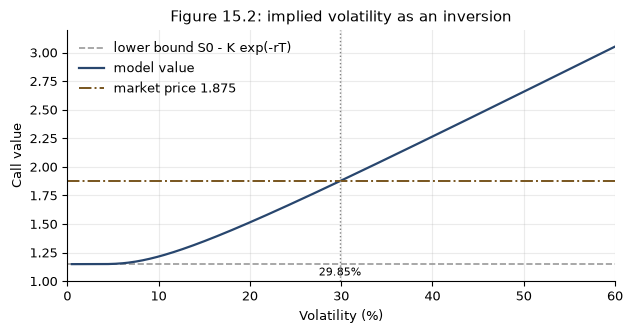

In [9]:
FIG_15_2 = ((0.5, 1.1494), (2, 1.1494), (4, 1.1497), (6, 1.1566), (8, 1.1789), (10, 1.2160),
            (14, 1.3199), (18, 1.4466), (22, 1.5853), (26, 1.7308), (30, 1.8807), (34, 2.0333),
            (38, 2.1877), (42, 2.3435), (46, 2.5002), (50, 2.6576), (54, 2.8153), (58, 2.9734))
good = sum(abs(bsm(S_iv, K_iv, r_iv, x / 100, T_iv)[2] - v) <= 0.5e-4 for x, v in FIG_15_2)
show("Figure 15.2 points that reproduce, of 18", good, 18, 0)

vols = np.linspace(0.005, 0.60, 300)
fig, ax = plt.subplots()
ax.axhline(lower, color="0.6", ls="--", lw=1.2, label="lower bound S0 - K exp(-rT)")
ax.plot(100 * vols, [bsm(S_iv, K_iv, r_iv, v, T_iv)[2] for v in vols], color=BLUE, lw=1.6,
        label="model value")
ax.axhline(market, color=AMBER, ls="-.", lw=1.4, label="market price 1.875")
ax.axvline(100 * iv_brent, color="0.5", ls=":", lw=1.0)
ax.annotate("%.2f%%" % (100 * iv_brent), (100 * iv_brent, 1.05), ha="center", fontsize=8)
ax.set_xlim(0, 60); ax.set_ylim(1.0, 3.2)
ax.set_xlabel("Volatility (%)"); ax.set_ylabel("Call value")
ax.set_title("Figure 15.2: implied volatility as an inversion")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 6. 两种时钟（第 15.8 节）

方差按交易日累积，利息按日历日累积，因此 $d_1$ 中与 $\sigma^2T_{\text{交易}}/2$ 并列的是
$rT_{\text{日历}}$。对 30 个日历日后到期的期权，两个年化比例分别是 $21/252$ 与 $30/365$；
两者之比（$252/365$ 对 $21/30$）平均而言接近 1，所以混用两种惯例的错误不容易被察觉。
下面的函数把两者分开，本笔记本最后一节将它用于表 10.2 的期权链。

In [10]:
def call_two_clocks(S, K_, r_, sig, t_trading, t_calendar):
    """European call with variance over trading time and discounting over calendar time."""
    v = sig * sqrt(t_trading)
    d1_ = (log(S / K_) + r_ * t_calendar + 0.5 * v * v) / v
    return S * N(d1_) - K_ * exp(-r_ * t_calendar) * N(d1_ - v)


print("252/365 = %.4f，对比 21/30 = %.4f" % (252 / 365, 21 / 30))
print("30 天期权，sigma = 24%%：期内标准差 %.5f（21/252），对比 %.5f（30/365）"
      % (0.24 * sqrt(21 / 252), 0.24 * sqrt(30 / 365)))
for trading_days in (8, 10):
    print("14 个日历日中含 %d 个交易日：方差相对 14/365 差 %+.1f%%"
          % (trading_days, 100 * ((trading_days / 252) / (14 / 365) - 1)))

252/365 = 0.6904，对比 21/30 = 0.7000
30 天期权，sigma = 24%：期内标准差 0.06928（21/252），对比 0.06881（30/365）
14 个日历日中含 8 个交易日：方差相对 14/365 差 -17.2%
14 个日历日中含 10 个交易日：方差相对 14/365 差 +3.5%


## 7. 连续股息率（例 15.4）

把 $S_0$ 全部换成 $S_0e^{-qT}$。指数位于 1,500，执行价 1,550，股息率 2.5%；本章把
$d_1$、$d_2$ 与正态分布值印到六位小数，因此这里按六位比较。

In [11]:
d1i, d2i, ci, _ = bsm(1500.0, 1550.0, 0.04, 0.18, 0.5, q=0.025)
show("d1", d1i, -0.135056, 6)
show("d2", d2i, -0.262335, 6)
show("N(d1)", N(d1i), 0.446284, 6)
show("N(d2)", N(d2i), 0.396532, 6)
show("1500 e^{-0.0125} N(d1)", 1500 * exp(-0.0125) * N(d1i), 661.11, 2)
show("1550 e^{-0.02} N(d2)", 1550 * exp(-0.02) * N(d2i), 602.45, 2)
show("call", ci, 58.66, 2)
show("one contract at the $100 multiplier", 100 * ci, 5866, 0)
show("risk-neutral chance of finishing above 1,550, percent", 100 * N(d2i), 40, 0)
show("gain needed to reach the strike, percent", 100 * (1550 / 1500 - 1), 3.3, 1)

d1                                                      -0.135056   book    -0.135056   ok
d2                                                      -0.262335   book    -0.262335   ok
N(d1)                                                    0.446284   book     0.446284   ok
N(d2)                                                    0.396532   book     0.396532   ok
1500 e^{-0.0125} N(d1)                                 661.109957   book       661.11   ok
1550 e^{-0.02} N(d2)                                   602.453464   book       602.45   ok
call                                                    58.656493   book        58.66   ok
one contract at the $100 multiplier                   5865.649333   book         5866   ok
risk-neutral chance of finishing above 1,550, percent      39.653150   book           40   ok
gain needed to reach the strike, percent                 3.333333   book          3.3   ok


## 8. 已知现金股息，以及 $S^*$ 的波动率（例 15.5，习题 15.16）

先扣除股息现值，再对余额定价。本章随后指出，这一计算中的波动率属于 $S^*$ 而非 $S$。
附录 A 给出精确表述：$S^*$ 以更小的基数承担相同的绝对风险，因此
$\sigma^* \approx \sigma\,S/S^* = \sigma/(1 - \text{PV}(D)/S)$。先检验附录 A 自己的例子
（股息率 6%、2 年）；再看习题 15.16 问到的情形，即股息率 4%、5 年，此时
$\text{PV}(D)/S = 1 - e^{-0.2}$，调整幅度约 22%。最后几行显示，对 5 年期平值看涨期权
使用未调整的波动率会低估其价值。

In [12]:
pv1, pv2 = 0.80 * exp(-0.04 * 2 / 12), 0.80 * exp(-0.04 * 5 / 12)
show("PV of the two-month dividend", pv1, 0.7947)
show("PV of the five-month dividend", pv2, 0.7868)
show("PV of dividends", pv1 + pv2, 1.5815)
S_star = 50.0 - pv1 - pv2
show("S*", S_star, 48.4185)
c_div = bsm(S_star, 50.0, 0.04, 0.30, 0.5)[2]
c_nodiv = bsm(50.0, 50.0, 0.04, 0.30, 0.5)[2]
show("call on S*", c_div, 3.83, 2)
show("call on a stock paying nothing", c_nodiv, 4.70, 2)
show("value the dividends cost the call, percent", 100 * (1 - c_div / c_nodiv), 18.5, 1)

print()
ratio6 = 1 - exp(-0.06 * 2)
show("Appendix A, 6% yield, two years: PV(D)/S", ratio6, 0.113, 3)
show("Appendix A: sigma*/sigma - 1, percent", 100 * (1 / (1 - ratio6) - 1), 13, 0)
ratio4 = 1 - exp(-0.04 * 5)
print("习题 15.16，股息率 4%%、5 年：PV(D)/S = %.4f，sigma*/sigma - 1 = %.1f%%"
      % (ratio4, 100 * (1 / (1 - ratio4) - 1)))
sig_star = 0.30 / (1 - ratio4)
S5 = 50.0 * (1 - ratio4)
print("S* = %.4f 上的 5 年期平值看涨期权：sigma = 30%% 时为 %.4f；按 sigma* 为 %.4f（sigma* = %.2f%%）"
      % (S5, bsm(S5, 50.0, 0.04, 0.30, 5.0)[2], bsm(S5, 50.0, 0.04, sig_star, 5.0)[2], 100 * sig_star))

PV of the two-month dividend                             0.794684   book       0.7947   ok
PV of the five-month dividend                            0.786777   book       0.7868   ok
PV of dividends                                          1.581462   book       1.5815   ok
S*                                                      48.418538   book      48.4185   ok
call on S*                                               3.825907   book         3.83   ok
call on a stock paying nothing                           4.695220   book         4.70   ok
value the dividends cost the call, percent              18.514863   book         18.5   ok

Appendix A, 6% yield, two years: PV(D)/S                 0.113080   book        0.113   ok
Appendix A: sigma*/sigma - 1, percent                   12.749685   book           13   ok
习题 15.16，股息率 4%、5 年：PV(D)/S = 0.1813，sigma*/sigma - 1 = 22.1%
S* = 40.9365 上的 5 年期平值看涨期权：sigma = 30% 时为 10.7534；按 sigma* 为 13.0159（sigma* = 36.64%）


## 9. 美式看跌期权：欧式下限与二叉树（第 15.10 节）

公式给出下限 $P \ge p$，格子方法给出美式价值。以第 13.9 节收敛图中的 2 年期看跌期权为例
（$S_0 = 50$，$K = 52$，$r = 5\%$，$\sigma = 30\%$），下限为 6.7601，2,000 步的树给出
7.4719，提前行权溢价为 10.5%。同一股票上 1 个月期的虚值看跌期权，溢价不到一个百分点。
图中显示下限在何处松弛：深度实值处，美式看跌期权值得行权，价值落在内在价值上，
欧式看跌期权则跌到内在价值之下。

European put, the formula                                6.760140   book       6.7601   ok
American put, 2,000-step tree                            7.471909   book       7.4719   ok
early-exercise premium, percent                         10.528910   book         10.5   ok


执行价 45 的 1 个月期看跌期权：欧式 0.2010，美式 0.2020，溢价 0.525%


执行价 48 的 1 个月期看跌期权：欧式 0.8119，美式 0.8179，溢价 0.739%


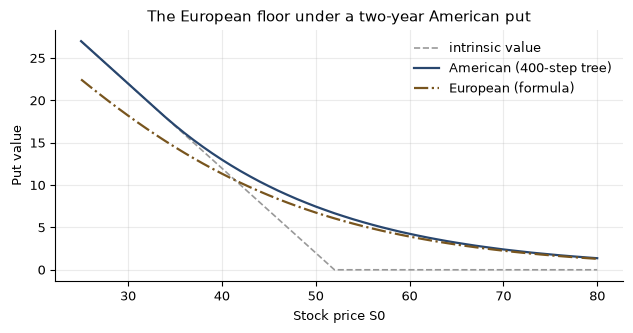

In [13]:
def crr_put(S, K_, r_, sig, t, steps, american=True):
    """Put on a Cox-Ross-Rubinstein tree; NumPy rolls each time slice back at once."""
    dt = t / steps
    up = exp(sig * sqrt(dt)); dn = 1.0 / up
    pu = (exp(r_ * dt) - dn) / (up - dn); disc = exp(-r_ * dt)
    j = np.arange(steps + 1)
    v = np.maximum(K_ - S * up ** j * dn ** (steps - j), 0.0)
    for i in range(steps - 1, -1, -1):
        v = disc * (pu * v[1:] + (1 - pu) * v[:-1])
        if american:
            j = np.arange(i + 1)
            v = np.maximum(v, K_ - S * up ** j * dn ** (i - j))
    return v[0]


euro_put = bsm(50.0, 52.0, 0.05, 0.30, 2.0)[3]
amer_put = crr_put(50.0, 52.0, 0.05, 0.30, 2.0, 2000)
show("European put, the formula", euro_put, 6.7601)
show("American put, 2,000-step tree", amer_put, 7.4719)
show("early-exercise premium, percent", 100 * (amer_put / euro_put - 1), 10.5, 1)
for strike in (45.0, 48.0):
    e = bsm(50.0, strike, 0.05, 0.30, 1 / 12)[3]
    a = crr_put(50.0, strike, 0.05, 0.30, 1 / 12, 2000)
    print("执行价 %.0f 的 1 个月期看跌期权：欧式 %.4f，美式 %.4f，溢价 %.3f%%"
          % (strike, e, a, 100 * (a / e - 1)))

spots = np.linspace(25.0, 80.0, 56)
fig, ax = plt.subplots()
ax.plot(spots, np.maximum(52.0 - spots, 0.0), color="0.6", ls="--", lw=1.2, label="intrinsic value")
ax.plot(spots, [crr_put(s, 52.0, 0.05, 0.30, 2.0, 400) for s in spots], color=BLUE, lw=1.6,
        label="American (400-step tree)")
ax.plot(spots, [bsm(s, 52.0, 0.05, 0.30, 2.0)[3] for s in spots], color=AMBER, ls="-.", lw=1.6,
        label="European (formula)")
ax.set_xlabel("Stock price S0"); ax.set_ylabel("Put value")
ax.set_title("The European floor under a two-year American put")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 10. 布莱克近似（例 15.6）

取两个欧式看涨期权中较大的一个：一个在 $T$ 到期、以股息调整后的价格为标的；一个在除息日
到期、以未调整的价格为标的。用来检验它的树把股息“托管”起来：在 Cox–Ross–Rubinstein
格点上对 $S^* = S - \text{PV}(D)$ 建模，并在除息日（含）之前的每个节点加回股息现值，
持有人可以在除息日带息行权。关闭提前行权后，这棵树必须重现 $S^*$ 上的欧式价值；
先做这一确认，再信任它。

布莱克近似在今天就从两种策略中选定一种，而持有人是在除息日看到股价之后才作选择。
它遗漏的正是这种推迟决定的选择权，因此树的价值总是更高；如本章所说，这里只高几美分。

In [14]:
S_b, K_b, r_b, sig_b, T_b, D, t1 = 52.0, 50.0, 0.04, 0.30, 0.5, 1.50, 5 / 12

show("K(1 - e^{-r(T - t1)})", K_b * (1 - exp(-r_b * (T_b - t1))), 0.17, 2)
pvD = D * exp(-r_b * t1)
show("PV(D)", pvD, 1.4752)
show("S* = S0 - PV(D)", S_b - pvD, 50.5248)
hold = bsm(S_b - pvD, K_b, r_b, sig_b, T_b)[2]
early = bsm(S_b, K_b, r_b, sig_b, t1)[2]
show("European to T on S*", hold, 5.00, 2)
show("European to t1 on S0", early, 5.48, 2)
black = max(hold, early)
show("Black's approximation", black, 5.48, 2)


def escrowed_call(S, K_, r_, sig, t, div, t_div, steps, american=True):
    """Call on a stock paying div at t_div: CRR tree on S* plus the dividend's PV up to t_div."""
    dt = t / steps
    up = exp(sig * sqrt(dt)); dn = 1.0 / up
    pu = (exp(r_ * dt) - dn) / (up - dn); disc = exp(-r_ * dt)
    i_div = int(round(t_div / dt))
    base = S - div * exp(-r_ * t_div)

    def stock(i):
        j = np.arange(i + 1)
        level = base * up ** j * dn ** (i - j)
        return level + div * exp(-r_ * (t_div - i * dt)) if i <= i_div else level

    v = np.maximum(stock(steps) - K_, 0.0)
    for i in range(steps - 1, -1, -1):
        v = disc * (pu * v[1:] + (1 - pu) * v[:-1])
        if american:
            v = np.maximum(v, stock(i) - K_)
    return v[0]


print()
print("%8s %14s %14s %14s" % ("steps", "European tree", "American tree", "tree - Black"))
for steps in (600, 1200, 3000):
    eu = escrowed_call(S_b, K_b, r_b, sig_b, T_b, D, t1, steps, american=False)
    am = escrowed_call(S_b, K_b, r_b, sig_b, T_b, D, t1, steps)
    print("%8d %14.4f %14.4f %11.2f cents" % (steps, eu, am, 100 * (am - black)))
print("欧式树收敛到 %.4f，即 S* 上的公式值；布莱克近似低于美式树的价值"
      % hold)

K(1 - e^{-r(T - t1)})                                    0.166389   book         0.17   ok
PV(D)                                                    1.475207   book       1.4752   ok
S* = S0 - PV(D)                                         50.524793   book      50.5248   ok
European to T on S*                                      5.004324   book         5.00   ok
European to t1 on S0                                     5.476015   book         5.48   ok
Black's approximation                                    5.476015   book         5.48   ok

   steps  European tree  American tree   tree - Black
     600         5.0059         5.5127        3.67 cents
    1200         5.0043         5.5118        3.58 cents


    3000         5.0046         5.5118        3.58 cents
欧式树收敛到 5.0043，即 S* 上的公式值；布莱克近似低于美式树的价值


## 11. 表 15.3 的偏斜（第 15.11 节）

用上面分开的两种时钟反解表 10.2 的看涨中间价：方差按 31 个交易日，执行价与第 11.6 节的
1.00 美元股息按 45 个日历日贴现，$S_0 = 48.30$，$r = 5\%$。若模型正确，六个隐含波动率
应当相等；它们却从 56.9% 降到 33.2%，最高者是最低者的 1.7 倍。这些看涨期权是美式的，如本章所说，
每个数字中都并入了一部分提前行权溢价，执行价越低，这部分越大。

最后一张表用最接近平值的 47.50 执行价读出的单一波动率为整条期权链定价，这正是本章所说的
“使用一个已被市场否定的模型”：低执行价被定得偏低，高执行价被定得偏高。这一比较是本笔记本
补充的，正文中没有。

境内市场的差异（欧式行权、ETF 期权分红调整合约条款而不调整标的价格、停牌与涨跌停对历史
波动率的影响，以及境内偏斜的读法）见第 15.12 节；那一节是制度性的讨论，没有需要在这里
重算的数字，只有本笔记本第 4 节已列出的 $\sqrt{242}$。

  strike  moneyness   call mid  implied vol         book
   42.50     -12.0%      6.650        56.9%        56.9%
  K = 42.50 moneyness, percent                         -12.008282   book        -12.0   ok
  K = 42.50 implied volatility, percent                 56.930574   book         56.9   ok
   45.00      -6.8%      4.425        46.0%        46.0%
  K = 45.00 moneyness, percent                          -6.832298   book         -6.8   ok
  K = 45.00 implied volatility, percent                 45.970819   book         46.0   ok
   47.50      -1.7%      2.670        39.7%        39.7%
  K = 47.50 moneyness, percent                          -1.656315   book         -1.7   ok
  K = 47.50 implied volatility, percent                 39.664925   book         39.7   ok
   50.00       3.5%      1.475        36.7%        36.7%
  K = 50.00 moneyness, percent                           3.519669   book          3.5   ok
  K = 50.00 implied volatility, percent                 36.700156   book      

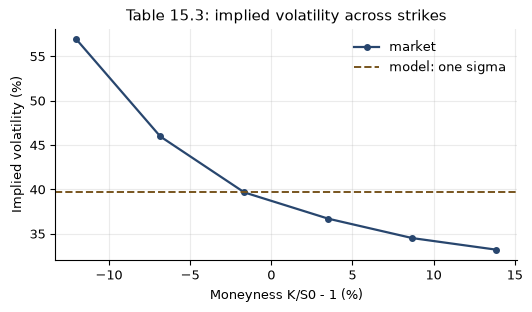

In [15]:
S_c, r_c = 48.30, 0.05
T_trd, T_cal = 31 / 252, 45 / 365
S_adj = S_c - 1.00 * exp(-r_c * T_cal)
TABLE_15_3 = ((42.50, -12.0, 6.650, 56.9), (45.00, -6.8, 4.425, 46.0), (47.50, -1.7, 2.670, 39.7),
              (50.00, 3.5, 1.475, 36.7), (52.50, 8.7, 0.710, 34.5), (55.00, 13.9, 0.305, 33.2))

print("%8s %10s %10s %12s %12s" % ("strike", "moneyness", "call mid", "implied vol", "book"))
ivs, money = [], []
for strike, mny, mid, book in TABLE_15_3:
    iv = brentq(lambda v: call_two_clocks(S_adj, strike, r_c, v, T_trd, T_cal) - mid, 0.01, 3.0)
    ivs.append(iv); money.append(100 * (strike / S_c - 1))
    print("%8.2f %9.1f%% %10.3f %11.1f%% %11.1f%%" % (strike, money[-1], mid, 100 * iv, book))
    show("  K = %.2f moneyness, percent" % strike, money[-1], mny, 1)
    show("  K = %.2f implied volatility, percent" % strike, 100 * ivs[-1], book, 1)
show("ratio of the extremes", ivs[0] / ivs[-1], 1.7, 1)

flat = ivs[2]
print()
print("%8s %10s %14s %12s" % ("strike", "call mid", "at one sigma", "model - mid"))
for (strike, _, mid, _), iv in zip(TABLE_15_3, ivs):
    model = call_two_clocks(S_adj, strike, r_c, flat, T_trd, T_cal)
    print("%8.2f %10.3f %14.3f %+12.3f" % (strike, mid, model, model - mid))

fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.plot(money, [100 * v for v in ivs], color=BLUE, lw=1.6, marker="o", ms=4, label="market")
ax.axhline(100 * flat, color=AMBER, ls="--", lw=1.4, label="model: one sigma")
ax.set_xlabel("Moneyness K/S0 - 1 (%)"); ax.set_ylabel("Implied volatility (%)")
ax.set_title("Table 15.3: implied volatility across strikes")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()